Epoch 1/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6606 - loss: 0.9929 - val_accuracy: 0.7700 - val_loss: 0.6702
Epoch 2/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8100 - loss: 0.5551 - val_accuracy: 0.7950 - val_loss: 0.6343
Epoch 3/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8433 - loss: 0.4612 - val_accuracy: 0.7950 - val_loss: 0.6239
Epoch 4/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 999us/step - accuracy: 0.8633 - loss: 0.3984 - val_accuracy: 0.8100 - val_loss: 0.6113
Epoch 5/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8761 - loss: 0.3485 - val_accuracy: 0.8200 - val_loss: 0.5963
Epoch 6/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8922 - loss: 0.3055 - val_accuracy: 0.8200 - val_loss: 0.5981
Epoch 7/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9083 - loss: 0.2699 - val_accuracy: 0.8100 - val_loss: 0.6188
Epoch 8/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9172 - loss: 0.2408 - val_accuracy: 0.8050 - val_los

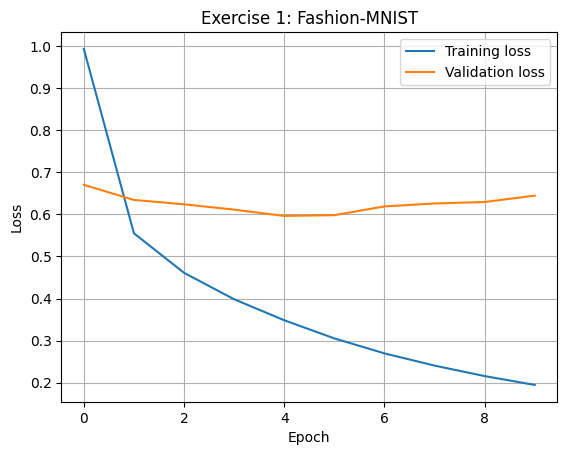

In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

# Import data
fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()

(X_train_full, y_train_full), (X_test_full, y_test_full) = fashion_mnist
X_train, y_train = X_train_full[:2000] / 255.0, y_train_full[:2000]
X_test,  y_test  = X_test_full[:400]  / 255.0, y_test_full[:400]

tf.keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),
    keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),
    keras.layers.Dense(10, activation="softmax"),
])

model.compile(loss="sparse_categorical_crossentropy",
              optimizer=keras.optimizers.Nadam(learning_rate=0.001),
              metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                           restore_best_weights=True)

history = model.fit(X_train, y_train, epochs=50, batch_size=32,
                    validation_split=0.1, callbacks=[early_stop])

test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Exercise 1: Fashion-MNIST")
plt.legend(); plt.grid(); plt.show()

In [3]:
from sklearn.preprocessing import StandardScaler

X_train = X_train_full[:2000].reshape(-1, 784)
X_test  = X_test_full[:400].reshape(-1, 784)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

tf.keras.utils.set_random_seed(42)

model_exercise_3 = keras.Sequential([
    keras.Input(shape=(784, )),
    keras.layers.Dense(100, activation="selu", kernel_initializer="lecun_normal"),
    keras.layers.AlphaDropout(0.1),
    keras.layers.Dense(100, activation="selu", kernel_initializer="lecun_normal"),
    keras.layers.AlphaDropout(0.1),
    keras.layers.Dense(100, activation="selu", kernel_initializer="lecun_normal"),
    keras.layers.AlphaDropout(0.1),
    keras.layers.Dense(10, activation="softmax"),
])

model_exercise_3.compile(loss="sparse_categorical_crossentropy",
                         optimizer=keras.optimizers.Nadam(learning_rate=0.001),
                         metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                           restore_best_weights=True)

history = model_exercise_3.fit(X_train_scaled, y_train, epochs=50, batch_size=32,
                               validation_split=0.1, callbacks=[early_stop])

ModuleNotFoundError: No module named 'sklearn'

### Q3.1

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8200 - loss: 0.6669
Test accuracy: 82.00%


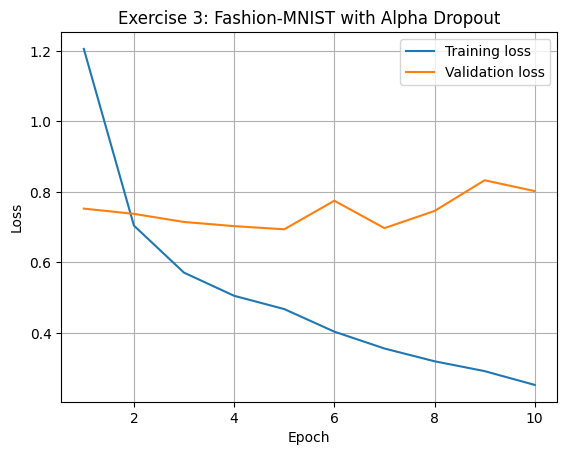

In [9]:
test_loss, test_acc = model_exercise_3.evaluate(X_test_scaled, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

epochs = range(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training loss")
plt.plot(epochs, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Exercise 3: Fashion-MNIST with Alpha Dropout")
plt.legend(); plt.grid(); plt.show()

### Q3.2

In [41]:
import numpy as np

y_probas = np.stack([model_exercise_3(X_test_scaled, training=True) for _ in range(20)])
y_proba = y_probas.mean(axis=0)

mc_acc = (y_proba.argmax(axis=1) == y_test).mean()
print(f"MC Dropout accuracy: {mc_acc * 100:.2f}%")

MC Dropout accuracy: 81.25%
